# 02 - Naive forecast, evaluation harness and master results table

Owner: **Group 202604-C5** Branch: `feature/evaluation`

**Purpose.** Every model in our group is judged in exactly the same way:

1. the same **walk-forward (expanding window) splits**, never shuffled,
2. the same **naive forecast** ("tomorrow = today", i.e. predicted log return = 0),
3. the same **metrics** (RMSE, MAE, out-of-sample R², directional accuracy),
4. the same **Diebold-Mariano (DM) test** against the naive forecast.

These live in `group_utils.py`, which wraps the lecturer's `tslab` functions so our numbers match Notebooks 3 and 4.

**Stock:** `JPM` · **Data downloaded on:** `2026-10-17` · **Seed:** 42

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tslab import config
from tslab.data import load_market_data
from tslab.features import make_dataset
from tslab.metrics import diebold_mariano

import group_utils as gu

np.random.seed(config.SEED)
pd.set_option("display.float_format", "{:.6f}".format)
print("Target ticker :", config.TARGET_TICKER)
print("INITIAL_TRAIN :", config.INITIAL_TRAIN, "rows")
print("TEST_SIZE     :", config.TEST_SIZE, "rows per fold")
print("Seed          :", config.SEED)

Target ticker : JPM
INITIAL_TRAIN : 1000 rows
TEST_SIZE     : 63 rows per fold
Seed          : 42


## 1. Load the modelling table

We use Richard's feature file (`data/features_JPM.csv`) when it has been merged. Until then we build the same table with `make_dataset`. This notebook only needs two columns: `target_return` (next-day log return, what every model predicts) and `close` (today's close, to turn a return into a price).

In [2]:
features_path = config.DATA_DIR / f"features_{config.TARGET_TICKER}.csv"
need = {"target_return", "close"}
dataset = None
if features_path.exists():
    dataset = pd.read_csv(features_path, index_col=0, parse_dates=True)
    if need.issubset(dataset.columns):
        print("Loaded Richard's features from", features_path)
    else:
        print("Missing columns", need - set(dataset.columns), "- using make_dataset")
        dataset = None
if dataset is None:
    dataset = make_dataset(load_market_data(), horizon=1)

dataset = dataset.dropna(subset=["target_return"])
print("Rows:", len(dataset), "| from", dataset.index[0].date(), "to", dataset.index[-1].date())

Loaded Richard's features from C:\BI\TmeSeriesForecastingandNeuralNetworks-c5\data\features_JPM.csv
Rows: 2790 | from 2015-10-16 to 2026-11-19


## 2. Walk-forward splits

Expanding window: each fold trains on **all** days before the test block and tests on the next 63 days (one quarter). The model never sees a test day while it is being trained. The check below proves that every training row comes before every test row and no test day is used twice.

In [3]:
splits = gu.get_splits(len(dataset))          # horizon = 1, so gap = 0
fold_table = gu.check_splits(splits, dataset.index)
print("Number of folds:", len(splits))
print("Test days in total:", sum(len(t) for _, t in splits))
fold_table.head()

Number of folds: 29
Test days in total: 1790


,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
1,1000,2015-10-16,2019-10-07,63,2019-10-08,2020-01-07
2,1063,2015-10-16,2020-01-07,63,2020-01-08,2020-04-07
3,1126,2015-10-16,2020-04-07,63,2020-04-08,2020-07-08
4,1189,2015-10-16,2020-07-08,63,2020-07-09,2020-10-06
5,1252,2015-10-16,2020-10-06,63,2020-10-07,2021-01-06


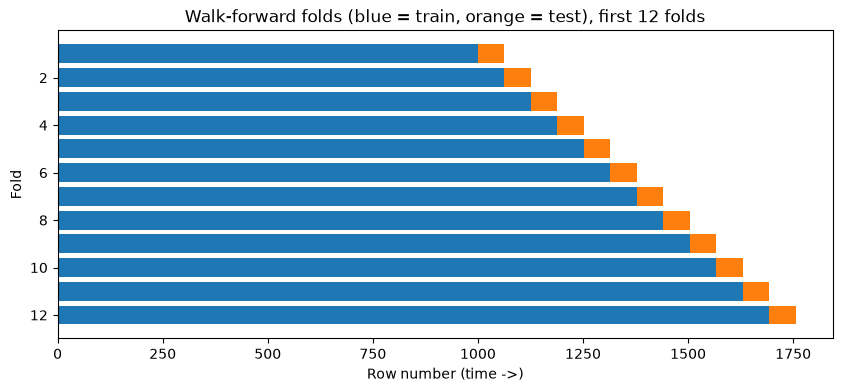

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
for k, (tr, te) in enumerate(splits[:12], start=1):
    ax.barh(k, len(tr), left=0, color="tab:blue")
    ax.barh(k, len(te), left=te[0], color="tab:orange")
ax.set_xlabel("Row number (time ->)"); ax.set_ylabel("Fold")
ax.set_title("Walk-forward folds (blue = train, orange = test), first 12 folds")
ax.invert_yaxis(); plt.show()

## 3. The naive forecast through the walk-forward splits

The naive forecast predicts a log return of 0, so its price forecast is **today's close**. It needs no training, but we still run it through the same folds so it is scored on the same days as every model.

We also add a second simple benchmark, **Drift**: the average return of the training block, recomputed in every fold (as in Notebook 3). It shows the harness working before the other models are merged.

In [5]:
y = dataset["target_return"]
naive = pd.Series(np.nan, index=dataset.index)
drift = pd.Series(np.nan, index=dataset.index)

for train_idx, test_idx in splits:
    naive.iloc[test_idx] = 0.0                                  # tomorrow = today
    drift.iloc[test_idx] = y.iloc[train_idx].mean()            # training block only

tested = naive.notna()
naive_scores = pd.Series(gu.score(y[tested], naive[tested], dataset.loc[tested, "close"]), name=gu.NAIVE_NAME)
print(naive_scores.to_string())
print(f"\nNaive directional accuracy is n/a (a zero forecast has no direction).")
print(f"Share of up days in the test period: {gu.share_of_up_days(y[tested]):.1%}")

gu.save_results("drift", y, drift)

RMSE (return)          0.018898
MAE (return)           0.012514
R2 out-of-sample       0.000000
Directional accuracy        NaN
RMSE (price)           2.981647
MAE (price)            2.017082

Naive directional accuracy is n/a (a zero forecast has no direction).
Share of up days in the test period: 53.4%
Saved 1790 predictions to C:\BI\TmeSeriesForecastingandNeuralNetworks-c5\results\drift.csv


WindowsPath('C:/BI/TmeSeriesForecastingandNeuralNetworks-c5/results/drift.csv')

## 4. Sanity checks on the harness

1. Our DM wrapper must give the same answer as `tslab.metrics.diebold_mariano`.
2. Our R² must match Notebook 3's definition: 1 − SSE(model) / SSE(zero forecast).
3. A model that copies the naive forecast must get R² = 0 and must not be "significant".

In [6]:
t, d = y[tested].values, drift[tested].values
ours = gu.dm_vs_naive(t, d)[:2]
lecturer = diebold_mariano(t, d, np.zeros(len(t)))
assert np.allclose(ours, lecturer), (ours, lecturer)

r2_by_hand = 1 - np.sum((t - d) ** 2) / np.sum(t ** 2)
assert np.isclose(gu.score(t, d)["R2 out-of-sample"], r2_by_hand)

assert np.isclose(gu.score(t, np.zeros(len(t)))["R2 out-of-sample"], 0.0)
print("All harness checks passed.")

All harness checks passed.


## 5. Master results table

After Arsene, Mark M. and Bakhita's PRs are merged, `results/` holds one CSV per model (`date, y_true, y_pred`). The table below scores **every model on the same dates**, puts the naive forecast in the **first row**, and adds the DM statistic and p-value against naive. It is saved to `data/metrics.csv` for Mark K's Power BI card.

*Rerun this cell after every merge.*

In [7]:
results = gu.load_results()
print("Models found in results/:", list(results))
master = gu.build_master_table(results, close=dataset["close"])
master

Models found in results/: ['drift']
Saved the master table to C:\BI\TmeSeriesForecastingandNeuralNetworks-c5\data\metrics.csv


,RMSE (return),MAE (return),R2 out-of-sample,Directional accuracy,RMSE (price),MAE (price),DM statistic,DM p-value,Verdict vs naive,Test days,Test from,Test to
Model,,,,,,,,,,,,
Naive (no change),0.018898,0.012514,0.000000,NaN,2.981647,2.017082,NaN,NaN,Benchmark,1790,2019-10-08,2026-11-19
Drift (training mean),0.018892,0.012484,0.000628,0.534078,2.980653,2.010412,-0.370106,0.711347,No significant difference,1790,2019-10-08,2026-11-19


In [8]:
candidates = master.drop(index=[gu.NAIVE_NAME, gu.MODEL_NAMES["drift"]], errors="ignore")
if candidates.empty:
    print("No real models merged yet (Drift is only a benchmark).")
else:
    best = candidates["RMSE (return)"].idxmin()
    row = master.loc[best]
    print(f"Best model by RMSE: {best}")
    print(f"  RMSE (price) {row['RMSE (price)']:.4f} vs naive {master.loc[gu.NAIVE_NAME, 'RMSE (price)']:.4f}")
    print(f"  DM statistic {row['DM statistic']:.3f}, p-value {row['DM p-value']:.3f} -> {row['Verdict vs naive']}")

No real models merged yet (Drift is only a benchmark).


## 6. Verdict for the client (draft - rewrite in our own words once all results are in)

**Our best model [does / does not] beat the naive "tomorrow = today" forecast on days it never saw.**

*How we know.* We tested every model on **N** trading days (from **…** to **…**) using walk-forward validation: each quarter the models were retrained on all earlier data and then asked to forecast a quarter they had never seen. The best model, **…**, had a price RMSE of **…** against **…** for the naive forecast. The Diebold-Mariano p-value was **…**; [because it is above 0.05, the difference could easily be chance / because it is below 0.05, the improvement is unlikely to be luck].

*How much to trust the 63-day forecast.* The 80% range for day 63 runs from **X** to **Y**. In testing, the actual price fell inside the 10–90% range **Z%** of the time (target 80%). Treat the central line as a rough guess; the range is the real message.

*Limitation.* **…** (e.g. the test period covers mostly one market regime; holidays are ignored in the forecast dates).